# SPHEREx DR1: cubo original de 102 canales y muestra de dos canales

El producto principal es `cubo_original`: los valores de IMAGE de los 102 canales de una tesela del All-Sky Cube oficial de IRSA DR1. No se reconstruye a partir de las imágenes L2. Los canales 1 y 2 se conservan como muestra para interpretar el producto.

El cubo tiene ejes `(canal, y, x)`. El cielo completo se distribuye en múltiples teselas: una sola tesela no contiene todo el cielo. IMAGE contiene el brillo; FLAGS contiene máscaras de bits de calidad y NHITS el número de contribuciones. Los canales espectrales no son una máscara de calidad.

Fuentes: [acceso a IRSA](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-access/) y [formato del producto](https://caltech-ipac.github.io/spherex-archive-documentation/spherex-data-products/).


In [8]:
# Ejecutar si faltan dependencias en el kernel de Jupyter:
# %pip install -U astroquery astropy numpy matplotlib

from pathlib import Path
from urllib.parse import urlparse
import re
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa
from IPython.display import display


## 1. Configuración

Por defecto se prueba una tesela de M101. Para todo el cielo usa `MODO = "allsky"` y `MAX_TESELAS = None`. La consulta obtiene metadatos; el procesamiento posterior lee los FITS secuencialmente y guarda solo dos planos por tesela. La transferencia puede incluir archivos completos según el servidor. Revisa espacio y tiempo disponibles antes de ejecutar el modo completo.


In [9]:
MODO = "region"  # "region" o "allsky"
MAX_TESELAS = 1   # None para procesar todas las teselas consultadas
COLECCION = "spherex_dr1_cube"
COORD = SkyCoord(ra=210.80227 * u.deg, dec=54.34895 * u.deg, frame="icrs")
RADIO = 1 * u.arcsec
SALIDA = Path("outputs/spherex_dr1_canales_1_2")
SOBRESCRIBIR = False

# Si cambia el esquema, especifica los nombres exactos mostrados en la sección 3.
COLUMNAS = {"centro": None, "inferior": None, "superior": None, "ancho": None}
# Solo se usa cuando una columna no declara unidad FITS; el cubo usa micrómetros.
UNIDAD_SIN_METADATA = u.um


In [10]:
if MODO not in {"region", "allsky"}:
    raise ValueError("MODO debe ser 'region' o 'allsky'")
if MAX_TESELAS is not None and MAX_TESELAS < 1:
    raise ValueError("MAX_TESELAS debe ser positivo o None")
kwargs = {"collection": [COLECCION]}
if MODO == "region":
    kwargs["pos"] = (COORD, RADIO)
results = Irsa.query_sia(**kwargs)
if len(results) == 0:
    raise RuntimeError("IRSA no devolvió teselas para esta consulta")
# Evitar copias repetidas de la misma URL, con orden reproducible.
urls = sorted({str(x).strip() for x in results["access_url"]
               if not np.ma.is_masked(x) and str(x).strip()})
if not urls:
    raise RuntimeError("La consulta no contiene access_url utilizables")
print(f"Teselas únicas consultadas: {len(urls)}")
urls_trabajo = urls if MAX_TESELAS is None else urls[:MAX_TESELAS]
print(f"Teselas a procesar: {len(urls_trabajo)}; modo: {MODO}")
display(results[:5])


Teselas únicas consultadas: 1
Teselas a procesar: 1; modo: region


s_ra,s_dec,facility_name,instrument_name,dataproduct_subtype,calib_level,dataproduct_type,energy_bandpassname,energy_emband,obs_id,s_resolution,em_min,em_max,em_res_power,proposal_title,access_url,access_format,access_estsize,t_exptime,s_region,obs_collection,obs_intent,algorithm_name,facility_keywords,instrument_keywords,environment_photometric,proposal_id,proposal_pi,proposal_project,target_name,target_type,target_standard,target_moving,target_keywords,obs_release_date,s_xel1,s_xel2,s_pixel_scale,position_timedependent,t_min,t_max,t_resolution,t_xel,obs_publisher_did,s_fov,em_xel,pol_states,pol_xel,cloud_access,o_ucd,upload_row_id
deg,deg,,,,,,,,,arcsec,m,m,,,,,kbyte,s,deg,,,,,,,,,,,,,,,,,,arcsec,,d,d,s,,,deg,,,,,,
float64,float64,object,object,object,int16,object,object,object,object,float64,float64,float64,float64,object,object,object,int64,float64,object,object,object,object,object,object,bool,object,object,object,object,object,bool,bool,object,object,int64,int64,float64,bool,float64,float64,float64,int64,object,float64,int64,object,int64,object,object,int64
211.875,54.34091230386124,SPHEREx,SPHEREx,science,3,cube,SPHEREx,Infrared,hips5_cube-hips_20261026,6.440000,7.455e-07,5.0096e-06,--,SPHEREx All-Sky Cube,https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix2858_cube.fits,image/fits,320910,--,POLYGON ICRS 211.30434782608694 55.87335043525198 213.75 54.340912303861245 212.39999999999998 52.801853781730614 209.99999999999997 54.340912303861245 211.30434782608694 55.87335043525198,spherex_dr1_cube,science,mosaic,,,--,,,SPHEREx,,,False,False,,2026-11-01 19:01:02,512,512,12.880,False,60789.848000,61174.472900,--,--,ivo://irsa.ipac/spherex_dr1_cube?hips5_cube-hips_20261026/2858,1.83,--,,--,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""key"":""dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix2858_cube.fits"", ""region"": ""us-east-1""}}",,1


## 2. Leer longitudes de onda y anchos de banda

La tabla `SPECTRAL_CHANNELS` es la autoridad espectral. El ancho se toma de una columna explícita si existe; en su defecto se calcula como borde superior menos borde inferior y se etiqueta como **anchura del intervalo**, sin asumir que sea FWHM. Si no hay ancho ni bordes, queda `NaN`. No se interpreta `em_max - em_min` de la consulta como ancho de un canal individual.


### Cubo original completo de la tesela

Se cargan los 102 planos sin seleccionar canales ni aplicar máscaras. Los canales sin cobertura se conservan tal como aparecen en el producto oficial. Las siguientes secciones extraen únicamente una muestra de dos canales.


In [ ]:
# Producto principal: todos los canales de la primera tesela original.
with fits.open(urls_trabajo[0], lazy_load_hdus=True) as hdul:
    cubo_original = hdul["IMAGE"].data.copy()
    canales_originales = Table(hdul["SPECTRAL_CHANNELS"].data)
    for columna_fits in hdul["SPECTRAL_CHANNELS"].columns:
        if columna_fits.unit:
            canales_originales[columna_fits.name].unit = columna_fits.unit
    wcs_original = WCS(hdul["IMAGE"].header, hdul).celestial
    header_original = hdul["IMAGE"].header.copy()
if cubo_original.ndim != 3 or cubo_original.shape[0] != 102:
    raise ValueError(f"Se esperaba un cubo de 102 canales; recibido {cubo_original.shape}")
print(cubo_original.shape)


In [11]:
def normalizar(nombre):
    return re.sub(r"[^a-z0-9]", "", nombre.lower())

ALIASES = {
    "centro": ["wavelength", "wave", "lambda", "lambda_center", "lambda_cen",
               "wave_center", "wave_cen", "central_wavelength", "wavelength_center", "center", "cwave"],
    "inferior": ["wave_min", "wavelength_min", "lambda_min", "lambda_low", "wave_low", "lower", "lower_edge", "min_wavelength"],
    "superior": ["wave_max", "wavelength_max", "lambda_max", "lambda_high", "wave_high", "upper", "upper_edge", "max_wavelength"],
    "ancho": ["bandwidth", "band_width", "delta_lambda", "delta_wave", "width", "cband"],
}

def columna(tabla, rol):
    manual = COLUMNAS[rol]
    if manual is not None:
        if manual not in tabla.colnames:
            raise ValueError(f"No existe {manual}; columnas: {tabla.colnames}")
        return manual
    nombres = {normalizar(n): n for n in tabla.colnames}
    for alias in ALIASES[rol]:
        if normalizar(alias) in nombres:
            return nombres[normalizar(alias)]
    return None

def valores_um(tabla, nombre):
    if nombre is None:
        return np.full(len(tabla), np.nan)
    c = tabla[nombre]
    unidad = u.Unit(c.unit) if c.unit else UNIDAD_SIN_METADATA
    return (np.asarray(np.ma.filled(c, np.nan), dtype=float) * unidad).to_value(u.um)

def seleccionar_canales(hdul):
    tabla = Table(hdul["SPECTRAL_CHANNELS"].data)
    # Table(FITS_rec) no conserva por sí sola las unidades TUNIT.
    for col in hdul["SPECTRAL_CHANNELS"].columns:
        if col.unit:
            tabla[col.name].unit = col.unit
    nombres = {rol: columna(tabla, rol) for rol in COLUMNAS}
    if nombres["centro"] is None:
        raise ValueError(f"Configura COLUMNAS['centro']. Esquema: {tabla.colnames}")
    centro = valores_um(tabla, nombres["centro"])
    if centro.ndim != 1 or len(centro) != hdul["IMAGE"].shape[0]:
        raise ValueError("Se espera una fila espectral por plano del cubo IMAGE")
    buenos = np.flatnonzero(np.isfinite(centro) & (centro > 0))
    indices = buenos[np.argsort(centro[buenos], kind="stable")][:2]
    if len(indices) != 2 or centro[indices[0]] == centro[indices[1]]:
        raise ValueError("No hay dos primeros canales con longitudes de onda distintas")
    inferior = valores_um(tabla, nombres["inferior"])[indices]
    superior = valores_um(tabla, nombres["superior"])[indices]
    ancho = valores_um(tabla, nombres["ancho"])[indices]
    origen = np.full(2, "no disponible", dtype="U32")
    valido = np.isfinite(ancho) & (ancho > 0)
    origen[valido] = "columna de ancho"
    bordes = ~valido & np.isfinite(inferior) & np.isfinite(superior) & (superior > inferior)
    ancho[~valido] = np.nan
    ancho[bordes] = superior[bordes] - inferior[bordes]
    origen[bordes] = "intervalo entre bordes"
    resumen = Table({"plano_original": indices, "lambda_centro": centro[indices],
                     "lambda_inferior": inferior, "lambda_superior": superior,
                     "ancho_banda": ancho, "origen_ancho": origen})
    for nombre in ["lambda_centro", "lambda_inferior", "lambda_superior", "ancho_banda"]:
        resumen[nombre].unit = u.um
    return indices, resumen, tabla


In [12]:
# Inspeccionar la primera tesela antes del procesamiento masivo.
with fits.open(urls_trabajo[0], lazy_load_hdus=True) as hdul:
    hdul.info()
    display(Table(hdul["SPECTRAL_CHANNELS"].data)[:3])
    print(hdul["SPECTRAL_CHANNELS"].columns)
    indices, resumen, _ = seleccionar_canales(hdul)
display(resumen)


Filename: /home/arjona/.cache/astropy/download/url/e015e3a80ad7170542b5534ffa1af6d3/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      15   ()      
  1  IMAGE         1 ImageHDU        47   (512, 512, 102)   float32   
  2  NHITS         1 ImageHDU        47   (512, 512, 102)   int32   
  3  FLAGS         1 ImageHDU       114   (512, 512, 102)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     35   102R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [102J, 102E, 102E]   


DETECTOR,SUBCHAN,WAVELENGTH,WL_MIN,WL_MAX,R,R_STD,BANDWIDTH
int16,int16,float32,float32,float32,float32,float32,float32
1,1,0.753,0.743,0.762,42.0,1.1,0.018
1,2,0.771,0.761,0.781,42.0,1.0,0.019
1,3,0.79,0.78,0.8,41.0,0.9,0.019


ColDefs(
    name = 'DETECTOR'; format = 'I'
    name = 'SUBCHAN'; format = 'I'
    name = 'WAVELENGTH'; format = 'E'; unit = 'um'; disp = 'F10.3'
    name = 'WL_MIN'; format = 'E'; unit = 'um'; disp = 'F10.3'
    name = 'WL_MAX'; format = 'E'; unit = 'um'; disp = 'F10.3'
    name = 'R'; format = 'E'; disp = 'F10.0'
    name = 'R_STD'; format = 'E'; disp = 'F10.1'
    name = 'BANDWIDTH'; format = 'E'; unit = 'um'; disp = 'F10.3'
)


plano_original,lambda_centro,lambda_inferior,lambda_superior,ancho_banda,origen_ancho
,um,um,um,um,
int64,float64,float64,float64,float64,str32
0,0.753000020980835,nan,nan,0.017999999225139618,columna de ancho
1,0.7710000276565552,nan,nan,0.01899999938905239,columna de ancho


## 3. Generar los cubos de dos canales y el manifiesto

Se conservan IMAGE, NHITS, FLAGS y la WCS espacial. `CHANNELS` contiene las coordenadas espectrales explícitas por plano; el eje 3 es un índice de canal, no una longitud de onda lineal inventada. `SPECTRAL_CHANNELS` conserva las filas originales seleccionadas. Los píxeles sin cobertura permanecen sin cobertura. No se aplican nuevas máscaras de calidad: usa FLAGS y NHITS para definirlas según tu análisis. El producto oficial ya tiene sustraída la luz zodiacal.


In [13]:
def extraer_tesela(url, destino):
    with fits.open(url, lazy_load_hdus=True) as hdul:
        indices, resumen, tabla = seleccionar_canales(hdul)
        primaria = fits.PrimaryHDU()
        primaria.header["ORIGIN"] = "SPHEREx DR1 / IRSA"
        primaria.header["HISTORY"] = f"Source: {url}"
        primaria.header["HISTORY"] = "Selected first two spectral channels by central wavelength."
        extensiones = [primaria]
        for nombre in ["IMAGE", "NHITS", "FLAGS"]:
            if nombre not in hdul:
                continue
            entrada = hdul[nombre]
            # section permite al lector acceder a los planos requeridos.
            datos = np.stack([entrada.section[int(i), :, :] for i in indices])
            header = WCS(entrada.header, hdul).celestial.to_header(relax=True)
            header["WCSAXES"] = 3
            header["CTYPE3"] = "CHANNEL"
            header["CRPIX3"] = 1.0
            header["CRVAL3"] = 1.0
            header["CDELT3"] = 1.0
            if "BUNIT" in entrada.header:
                header["BUNIT"] = entrada.header["BUNIT"]
            extensiones.append(fits.ImageHDU(datos, header=header, name=nombre))
        extensiones += [fits.BinTableHDU(resumen, name="CHANNELS"),
                        fits.BinTableHDU(tabla[indices], name="SPECTRAL_CHANNELS")]
        fits.HDUList(extensiones).writeto(destino, overwrite=SOBRESCRIBIR, checksum=True)
    return resumen

SALIDA.mkdir(parents=True, exist_ok=True)
manifest = Table(names=["url", "archivo", "estado", "detalle"], dtype=["U2048", "U512", "U16", "U2048"])
for numero, url in enumerate(urls_trabajo, 1):
    nombre = Path(urlparse(url).path).name
    destino = SALIDA / nombre.replace(".fits", "_canales_1_2.fits")
    print(f"[{numero}/{len(urls_trabajo)}] {nombre}")
    try:
        if destino.exists() and not SOBRESCRIBIR:
            estado = "existente"
        else:
            extraer_tesela(url, destino)
            estado = "generado"
        manifest.add_row((url, str(destino), estado, ""))
    except Exception as exc:
        manifest.add_row((url, str(destino), "error", str(exc)))
        print(f"Error: {exc}")
    manifest.write(SALIDA / "manifest.ecsv", format="ascii.ecsv", overwrite=True)
display(manifest)
print("Procesamiento completo de la selección:", not np.any(manifest["estado"] == "error"))


[1/1] Npix2858_cube.fits


url,archivo,estado,detalle
str2048,str512,str16,str2048
https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/hips5_cube/hips_20261026/Norder5/Dir0/Npix2858_cube.fits,outputs/spherex_dr1_canales_1_2/Npix2858_cube_canales_1_2.fits,existente,


Procesamiento completo de la selección: True


## 4. Visualizar una tesela y sus dos longitudes de onda

Esta figura muestra una tesela; no representa por sí sola el cielo completo. Para un mosaico global se requiere reproyectar las teselas a una malla común y tratar sus solapamientos.


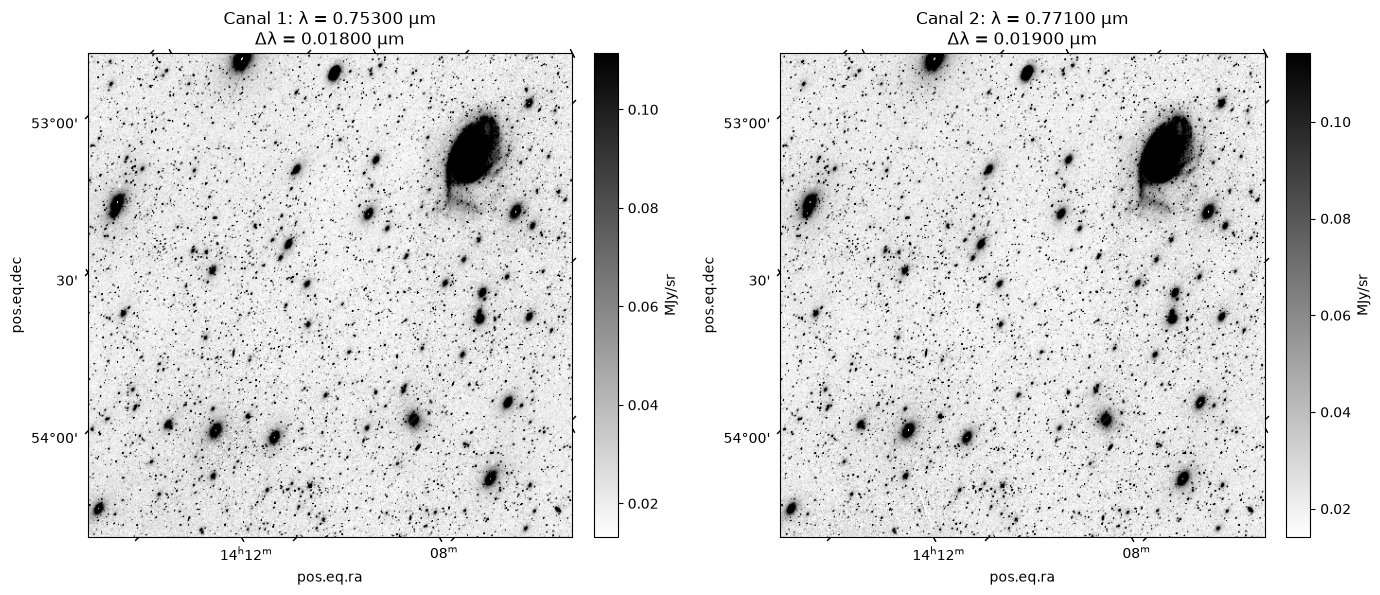

Forma del cubo: (2, 512, 512)


plano_original,lambda_centro,lambda_inferior,lambda_superior,ancho_banda,origen_ancho
int64,float64,float64,float64,float64,str32
0,0.753000020980835,nan,nan,0.017999999225139618,columna de ancho
1,0.7710000276565552,nan,nan,0.01899999938905239,columna de ancho


In [14]:
correctos = manifest[np.isin(manifest["estado"], ["generado", "existente"])]
if not len(correctos):
    raise RuntimeError("No hay cubos generados para visualizar; revisa manifest.ecsv")
with fits.open(str(correctos[0]["archivo"])) as hdul:
    cubo_espectral = hdul["IMAGE"].data.copy()
    canales = Table(hdul["CHANNELS"].data)
    wcs_cielo = WCS(hdul["IMAGE"].header).celestial
    unidad = hdul["IMAGE"].header.get("BUNIT", "unidad del FITS")
    fig = plt.figure(figsize=(14, 6))
    for i in range(2):
        ax = fig.add_subplot(1, 2, i + 1, projection=wcs_cielo)
        imagen = cubo_espectral[i]
        validos = imagen[np.isfinite(imagen)]
        limites = np.percentile(validos, [3.5, 96.5]) if validos.size else (0, 1)
        im = ax.imshow(imagen, origin="lower", cmap="gray_r", vmin=limites[0], vmax=limites[1])
        centro = canales["lambda_centro"][i]
        ancho = canales["ancho_banda"][i]
        texto = f"Δλ = {ancho:.5f} µm" if np.isfinite(ancho) else "Ancho no disponible"
        ax.set_title(f"Canal {i + 1}: λ = {centro:.5f} µm\n{texto}")
        ax.coords.grid(alpha=0.2)
        fig.colorbar(im, ax=ax, label=unidad, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()
print("Forma del cubo:", cubo_espectral.shape)
display(canales)
